1) Modify the PCA class to support inverse_transform. Reconstruct MNIST digits from 10, 50, and 200 components. Print the reconstruction error (mean squared difference from the original) for each.

Components: 300, Reconstruction MSE: 0.000492
Components: 50, Reconstruction MSE: 0.010305
Components: 200, Reconstruction MSE: 0.001538


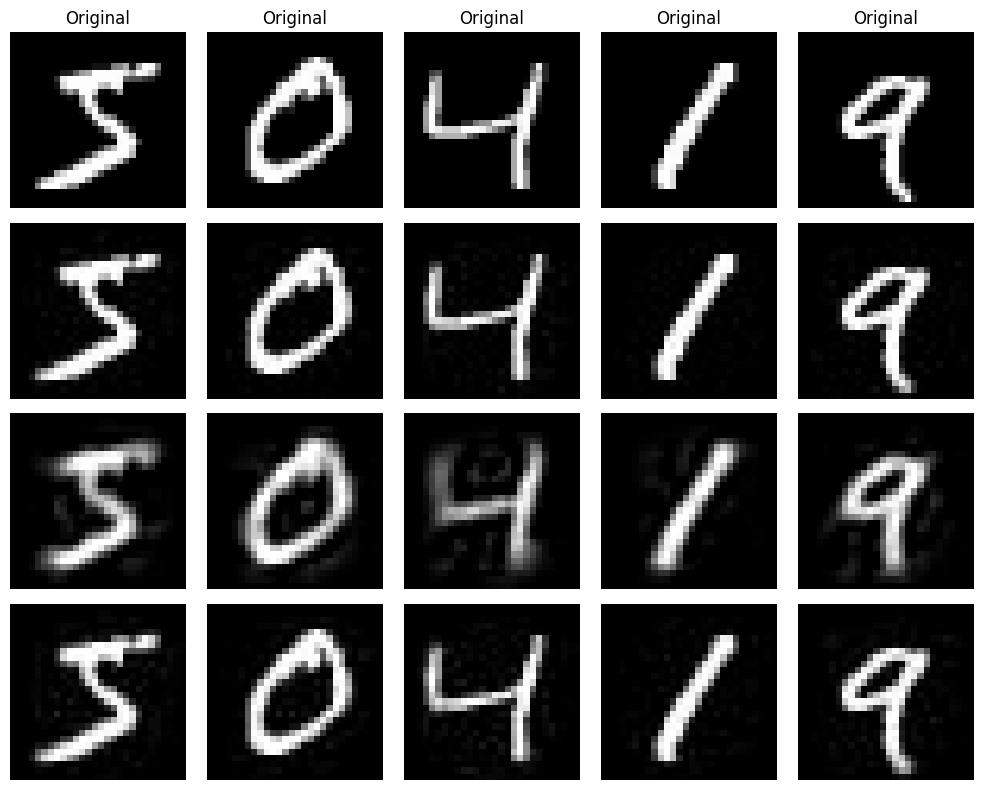

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.decomposition import PCA

mnist = fetch_openml("mnist_784", version=1, as_frame=False)

X = mnist.data[:1000].astype(np.float32) / 255.0

components = [300, 50, 200]
reconstructions = {}

for n in components:
    pca = PCA(n_components=n)

    X_reduced = pca.fit_transform(X)
    X_reconstructed = pca.inverse_transform(X_reduced)

    mse = np.mean((X - X_reconstructed) ** 2)

    reconstructions[n] = X_reconstructed

    print(f"Components: {n}, Reconstruction MSE: {mse:.6f}")

fig, axes = plt.subplots(4, 5, figsize=(10, 8))

for i in range(5):
    axes[0, i].imshow(X[i].reshape(28, 28), cmap="gray")
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

for row, n in enumerate(components, start=1):
    for i in range(5):
        axes[row, i].imshow(
            reconstructions[n][i].reshape(28, 28),
            cmap="gray",
            vmin=0,
            vmax=1
        )
        axes[row, i].axis("off")

    axes[row, 0].set_ylabel(f"{n} components")

plt.tight_layout()
plt.show()

2) Run t-SNE on the same MNIST subset with perplexity values of 5, 30, and 100. Describe how the output changes. Why does perplexity affect cluster tightness?


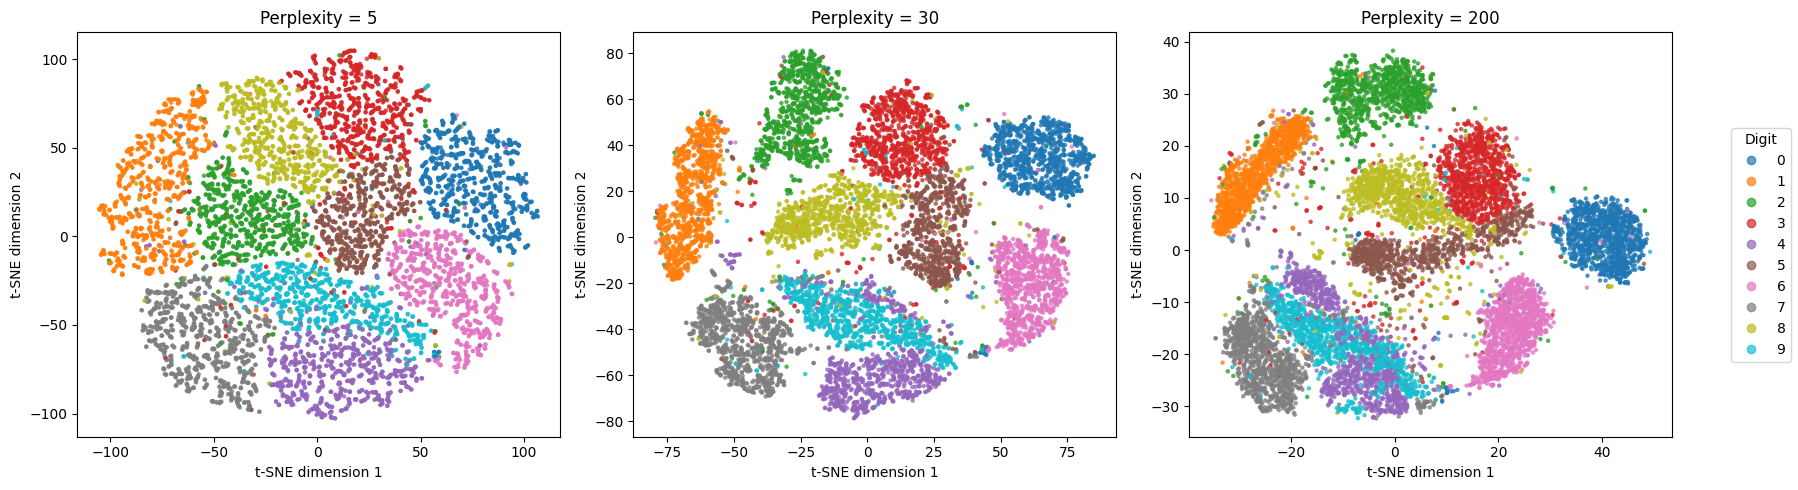

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.datasets import fetch_openml

mnist = fetch_openml("mnist_784", version=1, as_frame=False)

X = mnist.data[:10000].astype(np.float32) / 255.0
y = mnist.target[:10000].astype(int)

pca = PCA(n_components=50, random_state=42)
X_reduced = pca.fit_transform(X)

perplexities = [5, 30, 200]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, perplexity in zip(axes, perplexities):
    tsne = TSNE(
        n_components=2,
        perplexity=perplexity,
        init="pca",
        learning_rate="auto",
        max_iter=1000,
        random_state=42
    )

    X_2d = tsne.fit_transform(X_reduced)

    scatter = ax.scatter(
        X_2d[:, 0],
        X_2d[:, 1],
        c=y,
        cmap="tab10",
        s=5,
        alpha=0.7
    )

    ax.set_title(f"Perplexity = {perplexity}")
    ax.set_xlabel("t-SNE dimension 1")
    ax.set_ylabel("t-SNE dimension 2")

fig.legend(
    *scatter.legend_elements(),
    title="Digit",
    loc="center right"
)

plt.tight_layout(rect=[0, 0, 0.94, 1])
plt.show()

3) Take a dataset with 50 features where only 5 are informative (generate one with sklearn.datasets.make_classification). Apply PCA and check whether the explained variance curve correctly identifies that the data is effectively 5-dimensional.

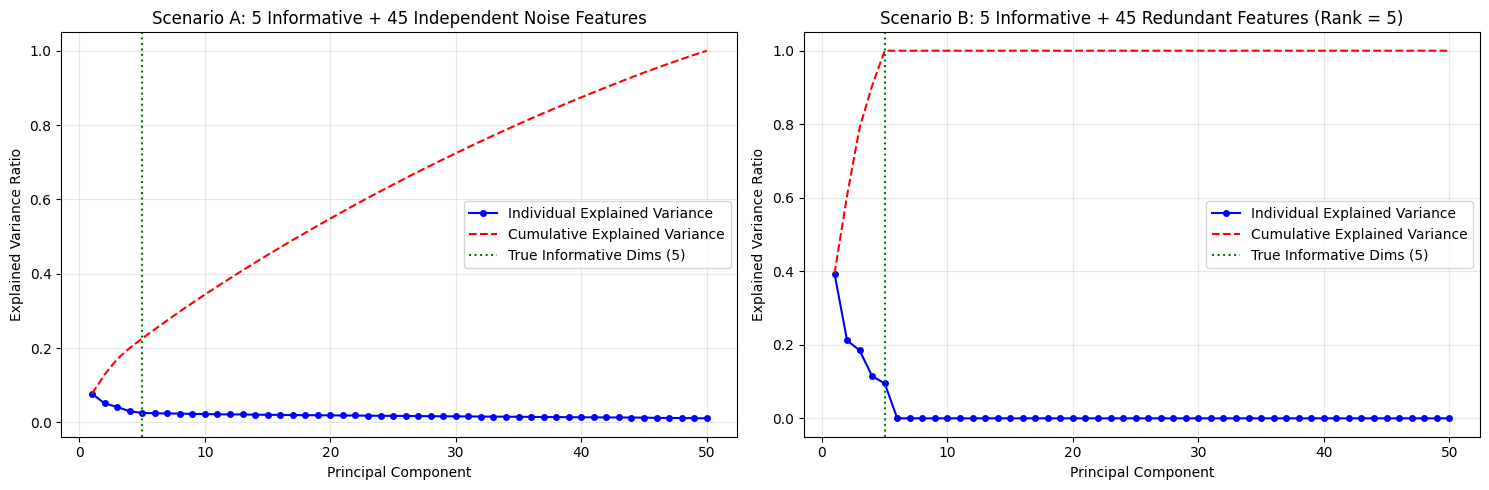

Scenario A (Noise)     - Top 5 components capture: 22.57% of total variance.
Scenario B (Redundant) - Top 5 components capture: 100.00% of total variance.


In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.decomposition import PCA


X_noise, y_noise = make_classification(
    n_samples=1000,
    n_features=50,
    n_informative=5,
    n_redundant=0,
    n_repeated=0,
    random_state=42
)

pca_noise = PCA().fit(X_noise)
exp_var_noise = pca_noise.explained_variance_ratio_
cum_var_noise = np.cumsum(exp_var_noise)


X_redundant, y_redundant = make_classification(
    n_samples=1000,
    n_features=50,
    n_informative=5,
    n_redundant=45,
    n_repeated=0,
    random_state=42
)

pca_redundant = PCA().fit(X_redundant)
exp_var_redundant = pca_redundant.explained_variance_ratio_
cum_var_redundant = np.cumsum(exp_var_redundant)


fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot Case 1: Noise features
axes[0].plot(range(1, 51), exp_var_noise, 'bo-', label='Individual Explained Variance', markersize=4)
axes[0].plot(range(1, 51), cum_var_noise, 'r--', label='Cumulative Explained Variance')
axes[0].axvline(x=5, color='green', linestyle=':', label='True Informative Dims (5)')
axes[0].set_title('Scenario A: 5 Informative + 45 Independent Noise Features')
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Explained Variance Ratio')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot Case 2: Redundant features
axes[1].plot(range(1, 51), exp_var_redundant, 'bo-', label='Individual Explained Variance', markersize=4)
axes[1].plot(range(1, 51), cum_var_redundant, 'r--', label='Cumulative Explained Variance')
axes[1].axvline(x=5, color='green', linestyle=':', label='True Informative Dims (5)')
axes[1].set_title('Scenario B: 5 Informative + 45 Redundant Features (Rank = 5)')
axes[1].set_xlabel('Principal Component')
axes[1].set_ylabel('Explained Variance Ratio')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Numerical comparison
print(f"Scenario A (Noise)     - Top 5 components capture: {cum_var_noise[4]*100:.2f}% of total variance.")
print(f"Scenario B (Redundant) - Top 5 components capture: {cum_var_redundant[4]*100:.2f}% of total variance.")
